# Restaurant Insights: NLP Extension
**Pune restaurant data (scraped from Zomato) → aspect classification of review tags → semantic restaurant search, with evaluation.**

This notebook extends the original EDA assignment (`main.ipynb`, left untouched). What it adds:

1. **Cleaning that fixes the data's real problems.** The same outlet appears once per area search, so 9,110 rows are only about 2,560 outlets.
2. **Aspect classification of the "People Say" tags** (food, service, ambience, value, delivery, other). The keyword rules from `main.ipynb` are the baseline. They are compared with a zero-shot embedding method and a supervised classifier, scored against a hand-labeled set of all 510 distinct tags.
3. **Semantic restaurant search** that uses the aspect classifier, evaluated on 30 written queries (those with at least 5 relevant outlets are scored).

**What this is not.** The tags are short, templated phrases (510 distinct), not full reviews, and there is no user interaction data. So this is aspect classification and retrieval over short tags, and it cannot test personalized recommendation. See the limitations at the end.

**How to run.** `pip install -r requirements.txt`, then `python -m spacy download en_core_web_md`. Optional: set `EMBED_BACKEND=sbert` to use sentence-transformers (`all-MiniLM-L6-v2`) instead of spaCy word vectors. Numbers below were produced with the spaCy backend.

In [1]:
import os, warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import f1_score
from nlp_core import *
from aspects import *
from search import *
sns.set_theme(style="whitegrid"); os.makedirs("figures", exist_ok=True); os.makedirs("outputs", exist_ok=True)
EMB = Embedder()   # EMBED_BACKEND=spacy (default) or sbert
print("embedding backend:", EMB.backend)

embedding backend: spacy


## 1. Load and clean
Problems found in the raw file, and what is done about each:

| Problem | Fix |
|---|---|
| The same outlet is listed under many areas (delivery radius), so rows are repeated | Collapse to one row per (name, address). When scrapes disagree on a rating, keep the row with the most votes |
| `-`, `New` and `0` stand for "missing" in rating and tag columns | Convert to NaN or an empty tag list. A rating with zero votes is treated as missing |
| Vote counts like `3,705` and `11.2K` are strings | Parse to numbers |
| Cost is `N for two people` for dine-in and `N for one order` for delivery-only | Keep the basis and compute a per-person cost |
| Encoding damage (`staff�s`) | Replace the broken character |

(`main.ipynb` also overwrote the original *Delivery Rating* column with its aspect score and never assigned the results of `fillna`. Those are avoided here.)

In [2]:
raw = clean_raw("data.csv")
outlets = dedupe_outlets(raw)
q33, q67 = outlets["cost_pp"].quantile([.33, .67])
facts = pd.Series({
    "scraped rows": len(raw),
    "unique outlets (name + address)": len(outlets),
    "outlets with a rating": int(outlets["rating"].notna().sum()),
    "outlets with at least one review tag": int((outlets["tags"].map(len) > 0).sum()),
    "total tag mentions (deduped per outlet)": int(outlets["tags"].map(len).sum()),
    "distinct tags": raw["tags"].explode().nunique(),
    "median cost per person (INR)": outlets["cost_pp"].median(),
})
facts

scraped rows                               9110.0
unique outlets (name + address)            2560.0
outlets with a rating                      2128.0
outlets with at least one review tag       1002.0
total tag mentions (deduped per outlet)    5681.0
distinct tags                               510.0
median cost per person (INR)                200.0
dtype: float64

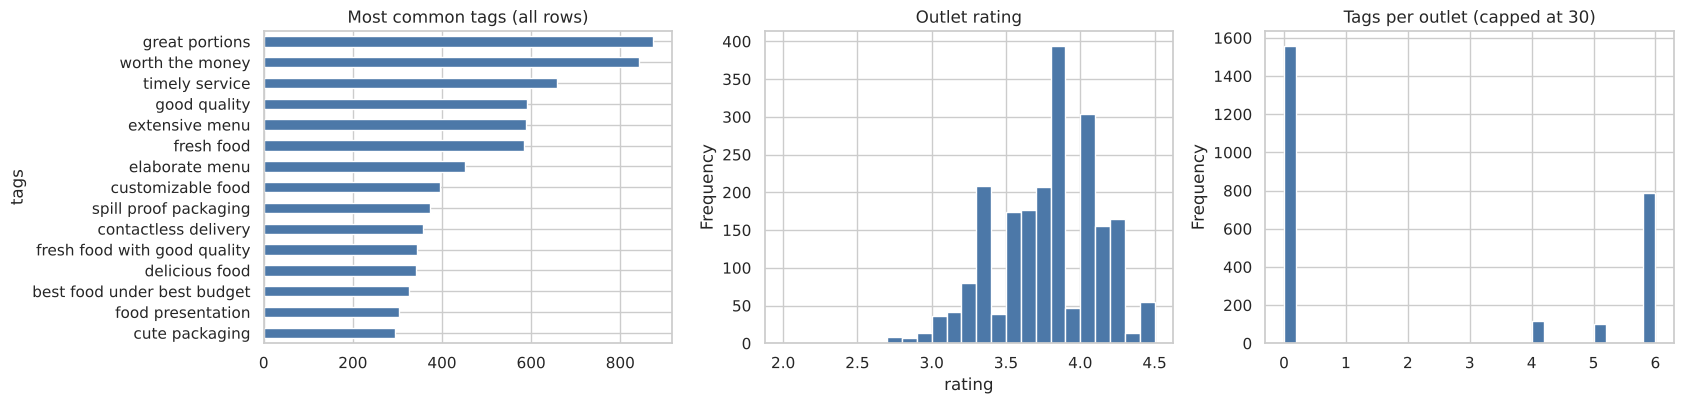

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
raw["tags"].explode().value_counts().head(15).iloc[::-1].plot.barh(ax=ax[0], color="#4C78A8"); ax[0].set_title("Most common tags (all rows)")
outlets["rating"].plot.hist(bins=25, ax=ax[1], color="#4C78A8"); ax[1].set_title("Outlet rating"); ax[1].set_xlabel("rating")
outlets["tags"].map(len).clip(upper=30).plot.hist(bins=30, ax=ax[2], color="#4C78A8"); ax[2].set_title("Tags per outlet (capped at 30)")
plt.tight_layout(); plt.savefig("figures/eda.png", dpi=130); plt.show()

## 2. Hand-labeled aspects for the 510 distinct tags
`labels/aspect_labels_draft.csv` assigns each distinct tag one or more of: **food, service, ambience, value, delivery, other**. They were labeled by reading each tag, **not** from the keyword rules, so they can serve as ground truth.

> ⚠️ **These are draft labels. Review them before you quote any metric.** Open the CSV and fix anything you disagree with, then re-run. Edge-case conventions: generic "place / spot / venue" → ambience; generic "restaurant / hotel / loved it" → other; portions → food; hygienic food → food but hygienic place → ambience. Because one labeler (not several) made the labels, there is no inter-annotator agreement number.

In [4]:
lab = pd.read_csv("labels/aspect_labels_draft.csv")
assert set(lab["tag"]) == set(raw["tags"].explode().dropna()), "labels must cover exactly the distinct tags"
tags_l, Y = lab["tag"].tolist(), lab[ASPECTS].values
freq = raw["tags"].explode().value_counts()
lab["freq"] = lab["tag"].map(freq)
print("tags per aspect:", dict(zip(ASPECTS, Y.sum(0))), "| multi-aspect tags:", int((Y.sum(1) > 1).sum()))
lab.sample(8, random_state=0)[["tag"] + ASPECTS]

tags per aspect: {'food': np.int64(157), 'service': np.int64(99), 'ambience': np.int64(170), 'value': np.int64(51), 'delivery': np.int64(34), 'other': np.int64(28)} | multi-aspect tags: 29


,tag,food,service,ambience,value,delivery,other
90,boneless chicken biryani,1,0,0,0,0,0
107,good food good quantity,1,0,0,0,0,0
336,games,0,0,1,0,0,0
499,best taste with best price,1,0,0,1,0,0
208,perfect service,0,1,0,0,0,0
15,good taste,1,0,0,0,0,0
437,prompt delivery,0,0,0,0,1,0
283,dhaba feel,0,0,1,0,0,0


## 3. Aspect classification: rules vs embeddings vs supervised
Three methods score each tag against the hand labels:

1. **Keyword rules**: the lexicon from `main.ipynb`, matched by substring (the baseline).
2. **Zero-shot**: cosine similarity between a tag embedding and a short description of each aspect. There is no training.
3. **Supervised**: one-vs-rest logistic regression on char n-gram TF-IDF plus the tag embedding.

Two tests are used. **5-fold cross-validation** gives the headline number. The **frequency split** is harder: train on the 250 most frequent tags and test on the 260 rarer ones, which have phrasing the model has not seen. Many tags are near-duplicates (for example "good packaging" and "good packing"), so the cross-validation number is optimistic, and the frequency split is the better guide to new phrasing.

In [5]:
from sklearn.model_selection import KFold
E_tags = EMB.encode(tags_l); E_desc = EMB.encode([DESCRIPTIONS[a] for a in ASPECTS])
P_rules = rule_predict(tags_l)
P_zero  = zero_shot_predict(E_tags, E_desc)
P_cv    = (oof_proba(tags_l, Y, EMB, n_splits=5, seed=0) >= 0.5).astype(int)      # out-of-fold predictions

order = lab["freq"].sort_values(ascending=False).index.values
tr, te = order[:250], order[250:]
am_split = AspectModel(EMB).fit(np.array(tags_l, dtype=object)[tr], Y[tr])
P_split = am_split.predict(np.array(tags_l, dtype=object)[te])

rows = []
for name, Pcv, Psp in [("Keyword rules (main.ipynb)", P_rules, P_rules[te]), ("Zero-shot embeddings", P_zero, P_zero[te]),
                       ("Supervised (char TF-IDF + embedding)", P_cv, P_split)]:
    a, b = prf(Y, Pcv), prf(Y[te], Psp)
    rows.append({"method": name, "CV micro-F1": a["micro_f1"], "CV macro-F1": a["macro_f1"],
                 "freq-split micro-F1": b["micro_f1"], "freq-split macro-F1": b["macro_f1"]})
results = pd.DataFrame(rows).set_index("method").round(3)
results.to_csv("outputs/aspect_classification_results.csv"); results

,CV micro-F1,CV macro-F1,freq-split micro-F1,freq-split macro-F1
method,,,,
Keyword rules (main.ipynb),0.631,0.670,0.627,0.662
Zero-shot embeddings,0.755,0.653,0.730,0.629
Supervised (char TF-IDF + embedding),0.905,0.854,0.876,0.786


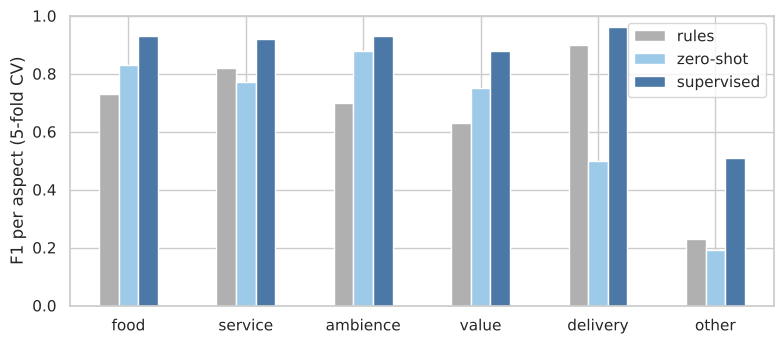

,rules,zero-shot,supervised
food,0.73,0.83,0.93
service,0.82,0.77,0.92
ambience,0.70,0.88,0.93
value,0.63,0.75,0.88
delivery,0.90,0.50,0.96
other,0.23,0.19,0.51


In [6]:
f1 = pd.DataFrame({"rules": f1_score(Y, P_rules, average=None), "zero-shot": f1_score(Y, P_zero, average=None),
                   "supervised": f1_score(Y, P_cv, average=None)}, index=ASPECTS).round(2)
ax = f1.plot.bar(figsize=(8, 3.6), color=["#B0B0B0", "#9ecae9", "#4C78A8"]); ax.set_ylabel("F1 per aspect (5-fold CV)"); ax.set_ylim(0, 1)
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig("figures/aspect_f1.png", dpi=130); plt.show(); f1

In [7]:
# Error analysis: where does the supervised model disagree with the labels?
pred_names = lambda row: "+".join(a for a, v in zip(ASPECTS, row) if v) or "-"
err = pd.DataFrame({"tag": tags_l, "gold": [pred_names(r) for r in Y], "pred": [pred_names(r) for r in P_cv],
                    "rules_pred": [pred_names(r) for r in P_rules], "freq": lab["freq"]})
wrong = err[err["gold"] != err["pred"]].sort_values("freq", ascending=False)
print(f"{len(wrong)} of {len(err)} tags differ from the label (exact match)"); wrong.head(15)

75 of 510 tags differ from the label (exact match)


,tag,gold,pred,rules_pred,freq
497,best food under best budget,food+value,food,food+value,325
214,good wifi,ambience,-,other,164
19,perfect presentation,food,ambience,other,131
20,weekend brunch,food,ambience,other,110
384,pocket friendly,value,-,other,99
23,wonderful presentation,food,-,other,91
222,good for large groups,ambience,food,other,75
386,economical,value,-,value,59
456,cafe,other,ambience,other,52
457,experience,other,-,other,48


## 4. Aspect profile per outlet
Each tag gets an **out-of-fold** aspect probability, from a model that never saw that tag's label. An outlet's profile is the mean of its tags' probabilities. Out-of-fold scoring keeps the search evaluation below honest, because the profiles never use the hand labels of the tags they describe.

In [8]:
P_oof = oof_proba(tags_l, Y, EMB, n_splits=5, seed=0)
tag_proba = dict(zip(tags_l, P_oof))
aspect_model = AspectModel(EMB).fit(tags_l, Y)       # for scoring new text (queries)
profile = np.array([np.mean([tag_proba[t] for t in T], axis=0) if T else np.zeros(len(ASPECTS)) for T in outlets["tags"]])
prof = pd.DataFrame(profile, columns=ASPECTS).assign(name=outlets["name"].values, n_tags=outlets["tags"].map(len).values,
                                                      votes=outlets["votes"].values)
for asp in ["service", "ambience", "value"]:
    top = prof[(prof["n_tags"] >= 6)].sort_values(asp, ascending=False).head(5)[["name", asp, "n_tags"]].round(2)
    print(f"\nTop outlets for {asp} (6+ tags):"); print(top.to_string(index=False))


Top outlets for service (6+ tags):
                            name  service  n_tags
                 Cheesiano Pizza     0.54       6
Siilver Spoon Family Resto & Bar     0.53       6
                       Pizza Hut     0.53       6
              Swarnaa Vegetarian     0.52       6
                             KFC     0.51       6

Top outlets for ambience (6+ tags):
          name  ambience  n_tags
     Marrakesh      0.98       6
The Irani Cafe      0.88       6
 Frozen Bottle      0.88       6
   Cream Stone      0.84       6
    Desi Dhaba      0.83       6

Top outlets for value (6+ tags):
                       name  value  n_tags
           Bikkgane Biryani   0.57       6
                Apna Punjab   0.54       6
Nosh Burgers and Sandwiches   0.51       6
                  Mad Momos   0.50       6
         Madinah Restaurant   0.49       6


## 5. Semantic restaurant search
Each outlet becomes a text document (cuisines, address, price band, tags). Retrieval systems are built from parts, so we can measure what each part adds:

| Part | What it does |
|---|---|
| `tfidf` / `embedding` | Base ranker: lexical or embedding similarity between query and document |
| `filters` | Hard filters parsed from the query: area, cuisine, cheap or premium |
| `prior` | Bayesian-averaged rating, so an outlet with 3 ratings does not beat one with 3,000 |
| `aspect` | The query's aspects (from the aspect classifier) × each outlet's aspect profile |

In [9]:
docs = build_docs(outlets, q33, q67)
S = Searcher(outlets, docs, EMB, q33, q67, tag_proba=tag_proba, aspect_model=aspect_model, w_prior=0.15, w_aspect=0.3)
full = "embedding+filters+prior+aspect"
for q in ["cozy place with a nice vibe in baner", "friendly staff and quick service in wakad", "inexpensive north indian food in kharadi"]:
    print("\nQUERY:", q); display(S.search(q, full, k=5).assign(address=lambda d: d["address"].str[:55]).round(2))


QUERY: cozy place with a nice vibe in baner


,name,address,cuisines,cost_pp,rating,score
244,Frozen Bottle,"Survey 1, Hissa 1/1, Revati Arcade, Baner, Pune","[Beverages, Desserts, Ice Cream, Shake]",200.0,4.00,0.90
706,La Pizzeria by Little Italy,"Shop F/B21, Ground Floor, High Street Complex,...","[Italian, Mexican, Fast Food, Beverages, Desse...",700.0,3.95,0.84
85,Marrakesh,"Shop 2, SR 85, Ground Floor, Vidhate Building,...","[Lebanese, North Indian, Mughlai, Biryani, Rol...",250.0,3.80,0.80
242,Cream Stone,"Ground Floor, Amar Business Park, Baner Road, ...","[Ice Cream, Desserts, Beverages, Shake]",200.0,4.30,0.77
741,Havmor Ice Cream,"Kalamkar Paradise Building, Balewadi Phata, Ba...","[Ice Cream, Desserts, Beverages, Shake]",150.0,4.20,0.76



QUERY: friendly staff and quick service in wakad


,name,address,cuisines,cost_pp,rating,score
359,Spice Factory,"2nd Floor, White Square, Hinjawadi Wakad Road,...","[North Indian, Chinese, Mughlai, Beverages]",1000.0,4.00,0.93
558,Siilver Spoon Family Resto & Bar,"Siddhi Nisarg, Bhumkar Chowk, Marunji Road, Wa...","[North Indian, Mughlai, Asian, Seafood, Contin...",550.0,3.70,0.91
126,Domino's Pizza,"Windsor Park, Shankar Kalat Nagar, Datta Mandi...","[Pizza, Fast Food, Beverages]",200.0,3.90,0.90
143,UFO Fries & Corn,"239/1E, Shop 1-2, Casapoli, Kaspate Wasti, Wak...","[Fast Food, Burger, Beverages, Shake, Pizza, W...",200.0,4.05,0.88
595,Barbeque Nation - Sayaji Hotel,"135/136, 10th Floor, Mumbai-Bangalore Bypass H...","[BBQ, Mughlai, Kebab, North Indian, Desserts]",850.0,4.05,0.88



QUERY: inexpensive north indian food in kharadi


,name,address,cuisines,cost_pp,rating,score
340,Thali Central,"Survey 56, Bootwala Estate, Aplay Ghar, Near S...","[North Indian, Desserts, Beverages]",150.0,3.7,1.12
526,Khichdi Etc,"52/1, Shreeram Nagar, Near Hindavi Battery, Kh...","[Healthy Food, North Indian]",150.0,4.0,1.11
1333,Comboman,"Shop 32, Kolte Patil Xenia, Vista A Tower, Kha...","[North Indian, Rolls, Sandwich, Beverages, Mug...",150.0,3.7,1.06
1220,Masala Mafia,"Shree Laxmi Narayan Niwas, Kharadkar Park, Kha...","[Chinese, North Indian, Ice Cream, Burger, Bev...",150.0,3.2,0.96
289,Masala Kitchen,"20/4, Shree Laxmi Narayan Niwas, Khandekar Par...","[North Indian, Fast Food, Chinese]",150.0,3.8,0.93


## 6. Evaluating the search
There are no user clicks, so relevance is **derived from structured fields and the hand-labeled tags**, and the retrieval systems never see those labels:

- area: the outlet's address contains the area name
- cuisine: the cuisine is in the outlet's cuisine list
- cheap or premium: cost per person in the bottom or top third
- aspect (for example service): at least 2 of the outlet's tags are labeled with that aspect

Queries are written in natural, paraphrased wording ("pocket friendly", "courteous waiters") so exact word overlap is not enough. Queries with fewer than 5 relevant outlets are skipped. Scores are precision@10 and NDCG@10.

**Caveats:** 30 queries written by one person, who had seen the data. The relevance rule comes from the same hand labels used to train the aspect model (but the profiles use out-of-fold predictions). Treat the numbers as a comparison between systems, not as an absolute measure of quality.

In [10]:
Q = [
 dict(text="inexpensive north indian food in wakad", area="wakad", cuisine="north indian", budget="cheap", kind="structured"),
 dict(text="pocket friendly chinese in kharadi", area="kharadi", cuisine="chinese", budget="cheap", kind="structured"),
 dict(text="affordable biryani near baner", area="baner", cuisine="biryani", budget="cheap", kind="structured"),
 dict(text="cheap desserts in viman nagar", area="viman-nagar", cuisine="desserts", budget="cheap", kind="structured"),
 dict(text="budget pizza in kalyani nagar", area="kalyani-nagar", cuisine="pizza", budget="cheap", kind="structured"),
 dict(text="inexpensive fast food in hinjawadi", area="hinjawadi", cuisine="fast food", budget="cheap", kind="structured"),
 dict(text="upscale north indian in koregaon park", area="koregaon-park", cuisine="north indian", budget="premium", kind="structured"),
 dict(text="affordable chinese in kothrud", area="kothrud", cuisine="chinese", budget="cheap", kind="structured"),
 dict(text="cheap burger in magarpatta", area="magarpatta", cuisine="burger", budget="cheap", kind="structured"),
 dict(text="budget friendly chinese in aundh", area="aundh", cuisine="chinese", budget="cheap", kind="structured"),
 dict(text="cozy place with a nice vibe in baner", area="baner", aspect="ambience", kind="aspect"),
 dict(text="relaxed atmosphere and good music in kharadi", area="kharadi", aspect="ambience", kind="aspect"),
 dict(text="lovely decor and comfortable seating in viman nagar", area="viman-nagar", aspect="ambience", kind="aspect"),
 dict(text="great hangout spot with a young crowd in kalyani nagar", area="kalyani-nagar", aspect="ambience", kind="aspect"),
 dict(text="friendly staff and quick service in wakad", area="wakad", aspect="service", kind="aspect"),
 dict(text="polite staff, prompt service in baner", area="baner", aspect="service", kind="aspect"),
 dict(text="courteous waiters in koregaon park", area="koregaon-park", aspect="service", kind="aspect"),
 dict(text="great value for money in kharadi", area="kharadi", aspect="value", kind="aspect"),
 dict(text="pocket friendly with big portions in wakad", area="wakad", aspect="value", kind="aspect"),
 dict(text="worth the price in viman nagar", area="viman-nagar", aspect="value", kind="aspect"),
 dict(text="fast delivery with good packaging in hadapsar", area="hadapsar", aspect="delivery", kind="aspect"),
 dict(text="safe contactless delivery in kothrud", area="kothrud", aspect="delivery", kind="aspect"),
 dict(text="quick delivery and proper packing in baner", area="baner", aspect="delivery", kind="aspect"),
 dict(text="cozy cheap north indian place in baner", area="baner", cuisine="north indian", budget="cheap", aspect="ambience", kind="mixed"),
 dict(text="affordable chinese with good service in kharadi", area="kharadi", cuisine="chinese", budget="cheap", aspect="service", kind="mixed"),
 dict(text="inexpensive pizza with fast delivery in wakad", area="wakad", cuisine="pizza", budget="cheap", aspect="delivery", kind="mixed"),
 dict(text="tasty food large portions in viman nagar", area="viman-nagar", aspect="food", kind="aspect"),
 dict(text="delicious biryani and fresh food in kalyani nagar", area="kalyani-nagar", cuisine="biryani", aspect="food", kind="mixed"),
 dict(text="amazing taste and extensive menu in kharadi", area="kharadi", aspect="food", kind="aspect"),
 dict(text="yummy desserts fresh and tasty in baner", area="baner", cuisine="desserts", aspect="food", kind="mixed"),
]
gold = {a: outlets["tags"].map(lambda T: sum(int(lab.set_index("tag").loc[t, a]) for t in T)) for a in ["food", "service", "ambience", "value", "delivery"]}
SYSTEMS = ["tfidf", "embedding", "tfidf+filters", "embedding+filters", "embedding+filters+prior", full]
res = evaluate(S, Q, gold, SYSTEMS, k=10)
kind = {q["text"]: q["kind"] for q in Q}; res["kind"] = res["query"].map(kind)
print(f"{res['query'].nunique()} of {len(Q)} queries kept (>= 5 relevant outlets)")
summary = res.groupby("system")[["p_at_k", "ndcg_at_k"]].mean().reindex(SYSTEMS).round(3).rename(columns={"p_at_k": "P@10", "ndcg_at_k": "NDCG@10"})
by_kind = res.groupby(["kind", "system"])["p_at_k"].mean().unstack("kind").reindex(SYSTEMS).round(2)
res.to_csv("outputs/search_eval_per_query.csv", index=False); summary.to_csv("outputs/search_eval_summary.csv")
display(summary); display(by_kind.rename_axis("P@10 by query type"))

20 of 30 queries kept (>= 5 relevant outlets)


,P@10,NDCG@10
system,,
tfidf,0.160,0.197
embedding,0.065,0.070
tfidf+filters,0.495,0.531
embedding+filters,0.620,0.675
embedding+filters+prior,0.620,0.684
embedding+filters+prior+aspect,0.735,0.813


kind,aspect,mixed,structured
P@10 by query type,,,
tfidf,0.15,0.2,0.20
embedding,0.08,0.0,0.02
tfidf+filters,0.38,0.2,1.00
embedding+filters,0.52,0.6,1.00
embedding+filters+prior,0.52,0.6,1.00
embedding+filters+prior+aspect,0.67,0.7,1.00


Adding the aspect component: mean change in P@10 = +0.115  (95% bootstrap CI +0.065 to +0.170, n=20 queries)


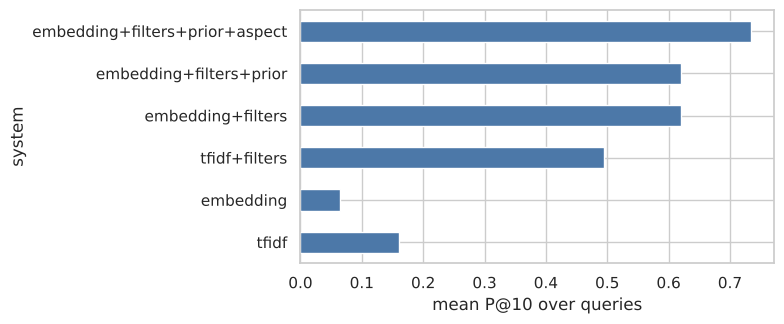

In [11]:
# How certain is the benefit of the aspect component? Bootstrap over queries (paired difference in P@10).
a = res[res.system == full].set_index("query")["p_at_k"]; b = res[res.system == "embedding+filters+prior"].set_index("query")["p_at_k"]
d = (a - b).dropna().values; rng = np.random.default_rng(0)
boot = [rng.choice(d, len(d)).mean() for _ in range(5000)]
print(f"Adding the aspect component: mean change in P@10 = {d.mean():+.3f}  (95% bootstrap CI {np.percentile(boot,2.5):+.3f} to {np.percentile(boot,97.5):+.3f}, n={len(d)} queries)")
ax = summary["P@10"].plot.barh(figsize=(8, 3.4), color="#4C78A8"); ax.set_xlabel("mean P@10 over queries"); plt.tight_layout()
plt.savefig("figures/search_eval.png", dpi=130); plt.show()

## 7. Optional: replace my relevance rule with your own judgments
`outputs/judgment_template.csv` lists the top 10 results of the full system for 10 queries. Fill in the `relevant` column (1 or 0) by looking at the restaurant's name, cuisines and tags. Judging by hand is a stronger evaluation than the rule above, and it takes about 15 minutes.

In [12]:
rows = []
for q in [x for x in Q if x["kind"] != "structured"][:10]:
    top = S.search(q["text"], full, k=10).reset_index(drop=True)
    for i, r in top.iterrows():
        tg = outlets.loc[outlets["name"] == r["name"], "tags"].iloc[0]
        rows.append(dict(query=q["text"], rank=i + 1, name=r["name"], address=r["address"], cuisines=", ".join(r["cuisines"]),
                         cost_pp=r["cost_pp"], tags="; ".join(tg[:8]), relevant=""))
pd.DataFrame(rows).to_csv("outputs/judgment_template.csv", index=False); print(len(rows), "rows written")

100 rows written


## 8. Limitations and what to claim
- **Tags, not reviews.** There are only 510 distinct short phrases, and nearly all are positive highlights, so this cannot measure sentiment. It classifies *what a tag is about*.
- **Few tags per outlet.** Zomato shows at most 6 tags per outlet, and 1,558 of the 2,560 outlets (61%) have none. Aspect profiles rest on 4 to 6 tags, and most outlets have no text signal, so they are ranked on cuisine, price, address and rating only.
- **Single labeler.** The labels are one person's reading, and many tags are near-duplicates, so the cross-validation scores are optimistic. Use the frequency-split numbers when describing generalization.
- **Synthetic relevance.** Search relevance is derived from structured fields plus hand labels, with 30 queries. It compares systems but is not a measure of real user satisfaction.
- **Static word vectors.** The spaCy backend averages word vectors. A sentence-transformer (`EMBED_BACKEND=sbert`) should do better on paraphrases, but was not run here.
- **No personalization.** There are no users or interactions, so collaborative filtering is not possible with this data.
- **Scraping.** The data was collected from Zomato by scraping, which its terms of service generally do not allow. Describe this as an academic project and avoid redistributing the data.

**Natural next steps:** LLM-based aspect extraction with a structured output compared against the models here, a faithfulness check on generated restaurant summaries, and hand-judged search relevance (Section 7).